# Class imbalance: comparing resampling strategies

The cleaned HCV data are very imbalanced (Healthy 533, Hepatitis 24, Fibrosis 21, Cirrhosis 30). This notebook compares ways of handling the small classes, using logistic regression and random forest.

To avoid leakage, the notebook starts from the unimputed data, and imputation, scaling and resampling are fitted inside each training fold.

In [1]:
# libraries: standard library first, then third-party packages
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from imblearn.combine import SMOTEENN, SMOTETomek
from imblearn.ensemble import (
    BalancedRandomForestClassifier, EasyEnsembleClassifier,
    RUSBoostClassifier,
)
from imblearn.over_sampling import (
    ADASYN, SMOTE, BorderlineSMOTE, RandomOverSampler,
)
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import wilcoxon
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    HistGradientBoostingClassifier, RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, make_scorer, precision_score, recall_score,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold, cross_val_predict, cross_validate,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

## Configuration

Settings are collected here. Cross-validation is five-fold, repeated five times, with a fixed seed so every strategy is tested on the same splits.

In [2]:
# file location (relative, so the notebook runs from the project folder)
DATA_PATH = Path("hcvdat0.csv")

# one seed everywhere so the results can be reproduced exactly
SEED = 42
ALPHA = 0.05

# Five-fold cross-validation repeated five times gives 25 test folds
N_SPLITS = 5
N_REPEATS = 5

# number of neighbours used when SMOTE-type methods invent new patients
K_NEIGHBORS = 5

# class order used in every table and chart
CLASSES = ["Healthy", "Hepatitis", "Fibrosis", "Cirrhosis"]

# predictors: 11 numeric measurements plus Sex
NUMERIC = ["Age", "ALB", "ALP", "ALT", "AST", "BIL", "CHE", "CHOL",
           "CREA", "GGT", "PROT"]
CATEGORICAL = ["Sex"]

# the strategy that every other strategy is compared against
BASELINE = "None (baseline)"

## Data loading and label cleaning

The labels are cleaned as in `cleaning.ipynb`. Missing values are left in place and filled inside each training fold later.

In [3]:
# read the raw file and drop the unnamed patient index column
raw_df = pd.read_csv(DATA_PATH)
df = raw_df.drop(columns=["Unnamed: 0"], errors="ignore").copy()

# remove the "0=", "1=" ... prefixes so only the diagnosis name remains
df["Category"] = df["Category"].str.replace(r"^[^=]*=", "", regex=True)

# drop the suspected blood donors, whose true status is uncertain
is_suspect = df["Category"].str.lower().str.contains("suspect")
df = df.loc[~is_suspect].reset_index(drop=True)

# use the clearer label "Healthy" for ordinary blood donors
df["Category"] = df["Category"].replace({"Blood Donor": "Healthy"})

# separate predictors (X) from the diagnosis (y). No imputation here
X = df[NUMERIC + CATEGORICAL]
y = df["Category"]

In [4]:
# check the size, the amount of missing data and the class counts
print(f"Rows: {len(df)}")
print(f"Missing predictor values: {int(X.isna().sum().sum())}")
display(y.value_counts().reindex(CLASSES).rename("Count").to_frame())

Rows: 608
Missing predictor values: 31


,Count
Category,
Healthy,533
Hepatitis,24
Fibrosis,21
Cirrhosis,30


## Cross-validation splits

The splits are made once and reused for every strategy.

In [5]:
# create the 25 train/test splits once; every strategy reuses this list
cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED
)
SPLITS = list(cv.split(X, y))

# confirm that even the smallest class has enough training patients
# for the nearest-neighbour step of SMOTE (needs more than 5)
min_train = min(
    (y.iloc[train] == "Fibrosis").sum() for train, _ in SPLITS
)
print(f"Number of splits: {len(SPLITS)}")
print(f"Smallest Fibrosis count in a training fold: {min_train}")

Number of splits: 25
Smallest Fibrosis count in a training fold: 16


## Strategies and pipelines

Each pipeline fills missing values with the median, scales the numeric variables, one-hot encodes Sex, then resamples and classifies. The `imblearn` pipeline applies the sampler to the training folds only.

In [6]:
# each strategy is a pair: (sampler or None, use class weights?)
# each pipeline receives its own fresh copy of the sampler
smote = SMOTE(k_neighbors=K_NEIGHBORS, random_state=SEED)
STRATEGIES = {
    BASELINE: (None, False),
    "class_weight=balanced": (None, True),
    "RandomOverSampler": (RandomOverSampler(random_state=SEED), False),
    "SMOTE": (smote, False),
    "BorderlineSMOTE": (
        BorderlineSMOTE(k_neighbors=K_NEIGHBORS, random_state=SEED), False),
    "ADASYN": (ADASYN(n_neighbors=K_NEIGHBORS, random_state=SEED), False),
    "SMOTETomek": (SMOTETomek(smote=smote, random_state=SEED), False),
    "SMOTEENN": (SMOTEENN(smote=smote, random_state=SEED), False),
    "RandomUnderSampler": (RandomUnderSampler(random_state=SEED), False),
}
MODELS = ["Logistic regression", "Random forest"]

In [7]:
# preprocessing is the same for all runs: median-impute and scale the
# numbers, one-hot encode sex. it sits inside the pipeline, so it is
# learned from the training folds only (no leakage from the test fold)
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])

# building one pipeline for every model and strategy
PIPELINES = {}
for model_name in MODELS:
    for strategy, (sampler, balanced) in STRATEGIES.items():

        # "balanced" makes rare classes count more during model fitting
        weight = "balanced" if balanced else None
        if model_name == "Logistic regression":
            classifier = LogisticRegression(
                max_iter=5000, class_weight=weight, random_state=SEED)
        else:
            classifier = RandomForestClassifier(
                n_estimators=300, min_samples_leaf=2, class_weight=weight,
                random_state=SEED, n_jobs=-1)

        # the sampler step is only added when the strategy has one
        steps = [("prep", preprocess)]
        if sampler is not None:
            steps.append(("sampler", clone(sampler)))
        steps.append(("clf", classifier))
        PIPELINES[(model_name, strategy)] = Pipeline(steps)

## Metrics

Macro F1 and balanced accuracy give every class the same weight. Recall for each class shows which classes a strategy helps or harms.

In [8]:
# overall scores that give every class the same weight
SCORING = {
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "macro_precision": make_scorer(
        precision_score, average="macro", zero_division=0),
}

# one recall score per class, so we can see who gains and who loses
for label in CLASSES:
    SCORING[f"recall_{label}"] = make_scorer(
        recall_score, labels=[label], average="macro", zero_division=0)

## Running all strategies

Every model and strategy is tested on the same 25 splits.

In [9]:
# some samplers print harmless warnings; hide them to keep output readable
warnings.filterwarnings("ignore", category=UserWarning)

# evaluating every model with every strategy on the same 25 splits
frames = []
for (model_name, strategy), pipeline in PIPELINES.items():

    # error_score="raise" stops the run if any fold fails, so a failure
    # (for example in ADASYN) can never be skipped without notice
    scores = cross_validate(
        pipeline, X, y, cv=SPLITS, scoring=SCORING, error_score="raise")

    # keeping only the test scores, one row per fold
    table = pd.DataFrame({
        name[len("test_"):]: values
        for name, values in scores.items() if name.startswith("test_")
    })
    table.insert(0, "fold", range(len(table)))
    table.insert(0, "strategy", strategy)
    table.insert(0, "model", model_name)
    frames.append(table)

# stacking the fold results of all runs
results = pd.concat(frames, ignore_index=True)
print(f"Fold-level rows: {len(results)}")

Fold-level rows: 450


## Mean and standard deviation per model and strategy

Mean (SD) over the 25 test folds.

In [10]:
# average each metric over the 25 folds, and measure its spread
METRICS = ["macro_f1", "balanced_accuracy", "macro_precision"]
METRICS += [f"recall_{c}" for c in CLASSES]
grouped = results.groupby(["model", "strategy"], sort=False)[METRICS]
mean_table = grouped.mean()
sd_table = grouped.std()

# combine into "mean (SD)" text for easy reading, one table per model
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
formatted = (mean_table.round(3).astype(str) + " ("
             + sd_table.round(3).astype(str) + ")")
for model_name in MODELS:
    print(model_name)
    display(formatted.loc[model_name])

Logistic regression


,macro_f1,balanced_accuracy,macro_precision,recall_Healthy,recall_Hepatitis,recall_Fibrosis,recall_Cirrhosis
strategy,,,,,,,
None (baseline),0.653 (0.082),0.625 (0.081),0.75 (0.116),0.995 (0.005),0.4 (0.199),0.366 (0.184),0.74 (0.205)
class_weight=balanced,0.602 (0.062),0.667 (0.073),0.584 (0.071),0.927 (0.028),0.578 (0.235),0.478 (0.168),0.687 (0.227)
RandomOverSampler,0.588 (0.057),0.649 (0.072),0.571 (0.068),0.923 (0.032),0.524 (0.249),0.45 (0.177),0.7 (0.198)
SMOTE,0.608 (0.055),0.66 (0.065),0.597 (0.064),0.935 (0.031),0.534 (0.22),0.458 (0.222),0.713 (0.19)
BorderlineSMOTE,0.617 (0.063),0.659 (0.076),0.622 (0.073),0.952 (0.02),0.546 (0.217),0.458 (0.23),0.68 (0.225)
ADASYN,0.596 (0.065),0.654 (0.072),0.577 (0.077),0.935 (0.026),0.578 (0.227),0.398 (0.225),0.707 (0.188)
SMOTETomek,0.608 (0.055),0.66 (0.065),0.597 (0.064),0.935 (0.031),0.534 (0.22),0.458 (0.222),0.713 (0.19)
SMOTEENN,0.593 (0.069),0.654 (0.075),0.576 (0.078),0.928 (0.032),0.542 (0.226),0.44 (0.246),0.707 (0.188)
RandomUnderSampler,0.608 (0.047),0.701 (0.056),0.587 (0.048),0.894 (0.041),0.604 (0.23),0.606 (0.176),0.7 (0.22)


Random forest


,macro_f1,balanced_accuracy,macro_precision,recall_Healthy,recall_Hepatitis,recall_Fibrosis,recall_Cirrhosis
strategy,,,,,,,
None (baseline),0.59 (0.091),0.566 (0.085),0.657 (0.13),0.996 (0.005),0.258 (0.229),0.258 (0.187),0.753 (0.199)
class_weight=balanced,0.641 (0.099),0.603 (0.099),0.747 (0.127),1.0 (0.002),0.348 (0.216),0.338 (0.242),0.727 (0.192)
RandomOverSampler,0.657 (0.097),0.629 (0.103),0.75 (0.118),0.997 (0.005),0.442 (0.25),0.358 (0.244),0.72 (0.185)
SMOTE,0.677 (0.082),0.68 (0.078),0.718 (0.12),0.99 (0.011),0.558 (0.276),0.344 (0.237),0.827 (0.148)
BorderlineSMOTE,0.668 (0.081),0.656 (0.086),0.732 (0.106),0.993 (0.008),0.458 (0.24),0.374 (0.217),0.8 (0.173)
ADASYN,0.666 (0.079),0.672 (0.074),0.706 (0.115),0.99 (0.012),0.548 (0.288),0.308 (0.223),0.84 (0.14)
SMOTETomek,0.679 (0.08),0.683 (0.077),0.719 (0.119),0.99 (0.011),0.566 (0.286),0.344 (0.237),0.833 (0.144)
SMOTEENN,0.677 (0.06),0.685 (0.056),0.722 (0.105),0.985 (0.013),0.574 (0.259),0.348 (0.208),0.833 (0.144)
RandomUnderSampler,0.593 (0.074),0.668 (0.089),0.577 (0.07),0.915 (0.029),0.494 (0.27),0.53 (0.267),0.733 (0.18)


## Ranking of strategies

Strategies are ranked within each model by macro F1 and by balanced accuracy.

In [11]:
# sort the strategies from best to worst within each model, once per
# headline metric, and number them
for metric in ["macro_f1", "balanced_accuracy"]:
    ranking = (
        mean_table[metric].round(3).rename(metric).reset_index()
        .sort_values(["model", metric], ascending=[True, False])
    )
    ranking["rank"] = ranking.groupby("model").cumcount() + 1
    print(f"Ranking by {metric}")
    display(ranking.set_index(["model", "rank"]))

Ranking by macro_f1


strategy  macro_f1
model               rank                                 
Logistic regression 1           None (baseline)     0.653
                    2           BorderlineSMOTE     0.617
                    3                     SMOTE     0.608
                    4                SMOTETomek     0.608
                    5        RandomUnderSampler     0.608
                    6     class_weight=balanced     0.602
                    7                    ADASYN     0.596
                    8                  SMOTEENN     0.593
                    9         RandomOverSampler     0.588
Random forest       1                SMOTETomek     0.679
                    2                     SMOTE     0.677
                    3                  SMOTEENN     0.677
                    4           BorderlineSMOTE     0.668
                    5                    ADASYN     0.666
                    6         RandomOverSampler     0.657
                    7     class_weight=balanced     0.641
                    8        RandomUnderSampler     0.593
                    9           None (baseline)     0.590

Ranking by balanced_accuracy


strategy  balanced_accuracy
model               rank                                          
Logistic regression 1        RandomUnderSampler              0.701
                    2     class_weight=balanced              0.667
                    3                     SMOTE              0.660
                    4                SMOTETomek              0.660
                    5           BorderlineSMOTE              0.659
                    6                    ADASYN              0.654
                    7                  SMOTEENN              0.654
                    8         RandomOverSampler              0.649
                    9           None (baseline)              0.625
Random forest       1                  SMOTEENN              0.685
                    2                SMOTETomek              0.683
                    3                     SMOTE              0.680
                    4                    ADASYN              0.672
                    5        RandomUnderSampler              0.668
                    6           BorderlineSMOTE              0.656
                    7         RandomOverSampler              0.629
                    8     class_weight=balanced              0.603
                    9           None (baseline)              0.566

## Paired differences against the baseline

Each strategy is compared with the baseline fold by fold, using a Wilcoxon signed-rank test with Bonferroni adjustment for the eight strategies.

The folds share training data, so the p-values are only a rough guide.

In [12]:
# compare each strategy with the baseline, fold by fold, because the
# splits are identical. A positive difference means better than baseline
rows = []
others = [name for name in STRATEGIES if name != BASELINE]
for model_name in MODELS:
    model_rows = results[results["model"] == model_name]
    for metric in ["macro_f1", "balanced_accuracy"]:
        base = model_rows[model_rows["strategy"] == BASELINE][metric]
        for strategy in others:
            scores = model_rows[model_rows["strategy"] == strategy][metric]
            diff = scores.to_numpy() - base.to_numpy()

            # Wilcoxon cannot run when all differences are zero; that
            # means no difference at all, so the p-value is set to 1
            if np.all(diff == 0):
                p_value = 1.0
            else:
                p_value = wilcoxon(diff).pvalue
            rows.append({"model": model_name, "metric": metric,
                         "strategy": strategy, "mean_diff": diff.mean(),
                         "p_raw": p_value})
paired = pd.DataFrame(rows)

# Bonferroni: multiply by the number of strategies tested (8), cap at 1
paired["p_adj"] = (paired["p_raw"] * len(others)).clip(upper=1)
paired["significant"] = paired["p_adj"] < ALPHA
paired[["mean_diff", "p_raw", "p_adj"]] = paired[
    ["mean_diff", "p_raw", "p_adj"]].round(4)
display(paired)

,model,metric,strategy,mean_diff,p_raw,p_adj,significant
0,Logistic regression,macro_f1,class_weight=balanced,-0.0517,0.0074,0.0590,False
1,Logistic regression,macro_f1,RandomOverSampler,-0.0652,0.0007,0.0057,True
2,Logistic regression,macro_f1,SMOTE,-0.0451,0.0393,0.3147,False
3,Logistic regression,macro_f1,BorderlineSMOTE,-0.0359,0.0422,0.3372,False
4,Logistic regression,macro_f1,ADASYN,-0.0570,0.0046,0.0368,True
5,Logistic regression,macro_f1,SMOTETomek,-0.0451,0.0393,0.3147,False
6,Logistic regression,macro_f1,SMOTEENN,-0.0600,0.0160,0.1278,False
7,Logistic regression,macro_f1,RandomUnderSampler,-0.0450,0.0125,0.0997,False
8,Logistic regression,balanced_accuracy,class_weight=balanced,0.0421,0.0105,0.0841,False
9,Logistic regression,balanced_accuracy,RandomOverSampler,0.0239,0.0588,0.4700,False


## Per-class recall by strategy

One bar chart per model.

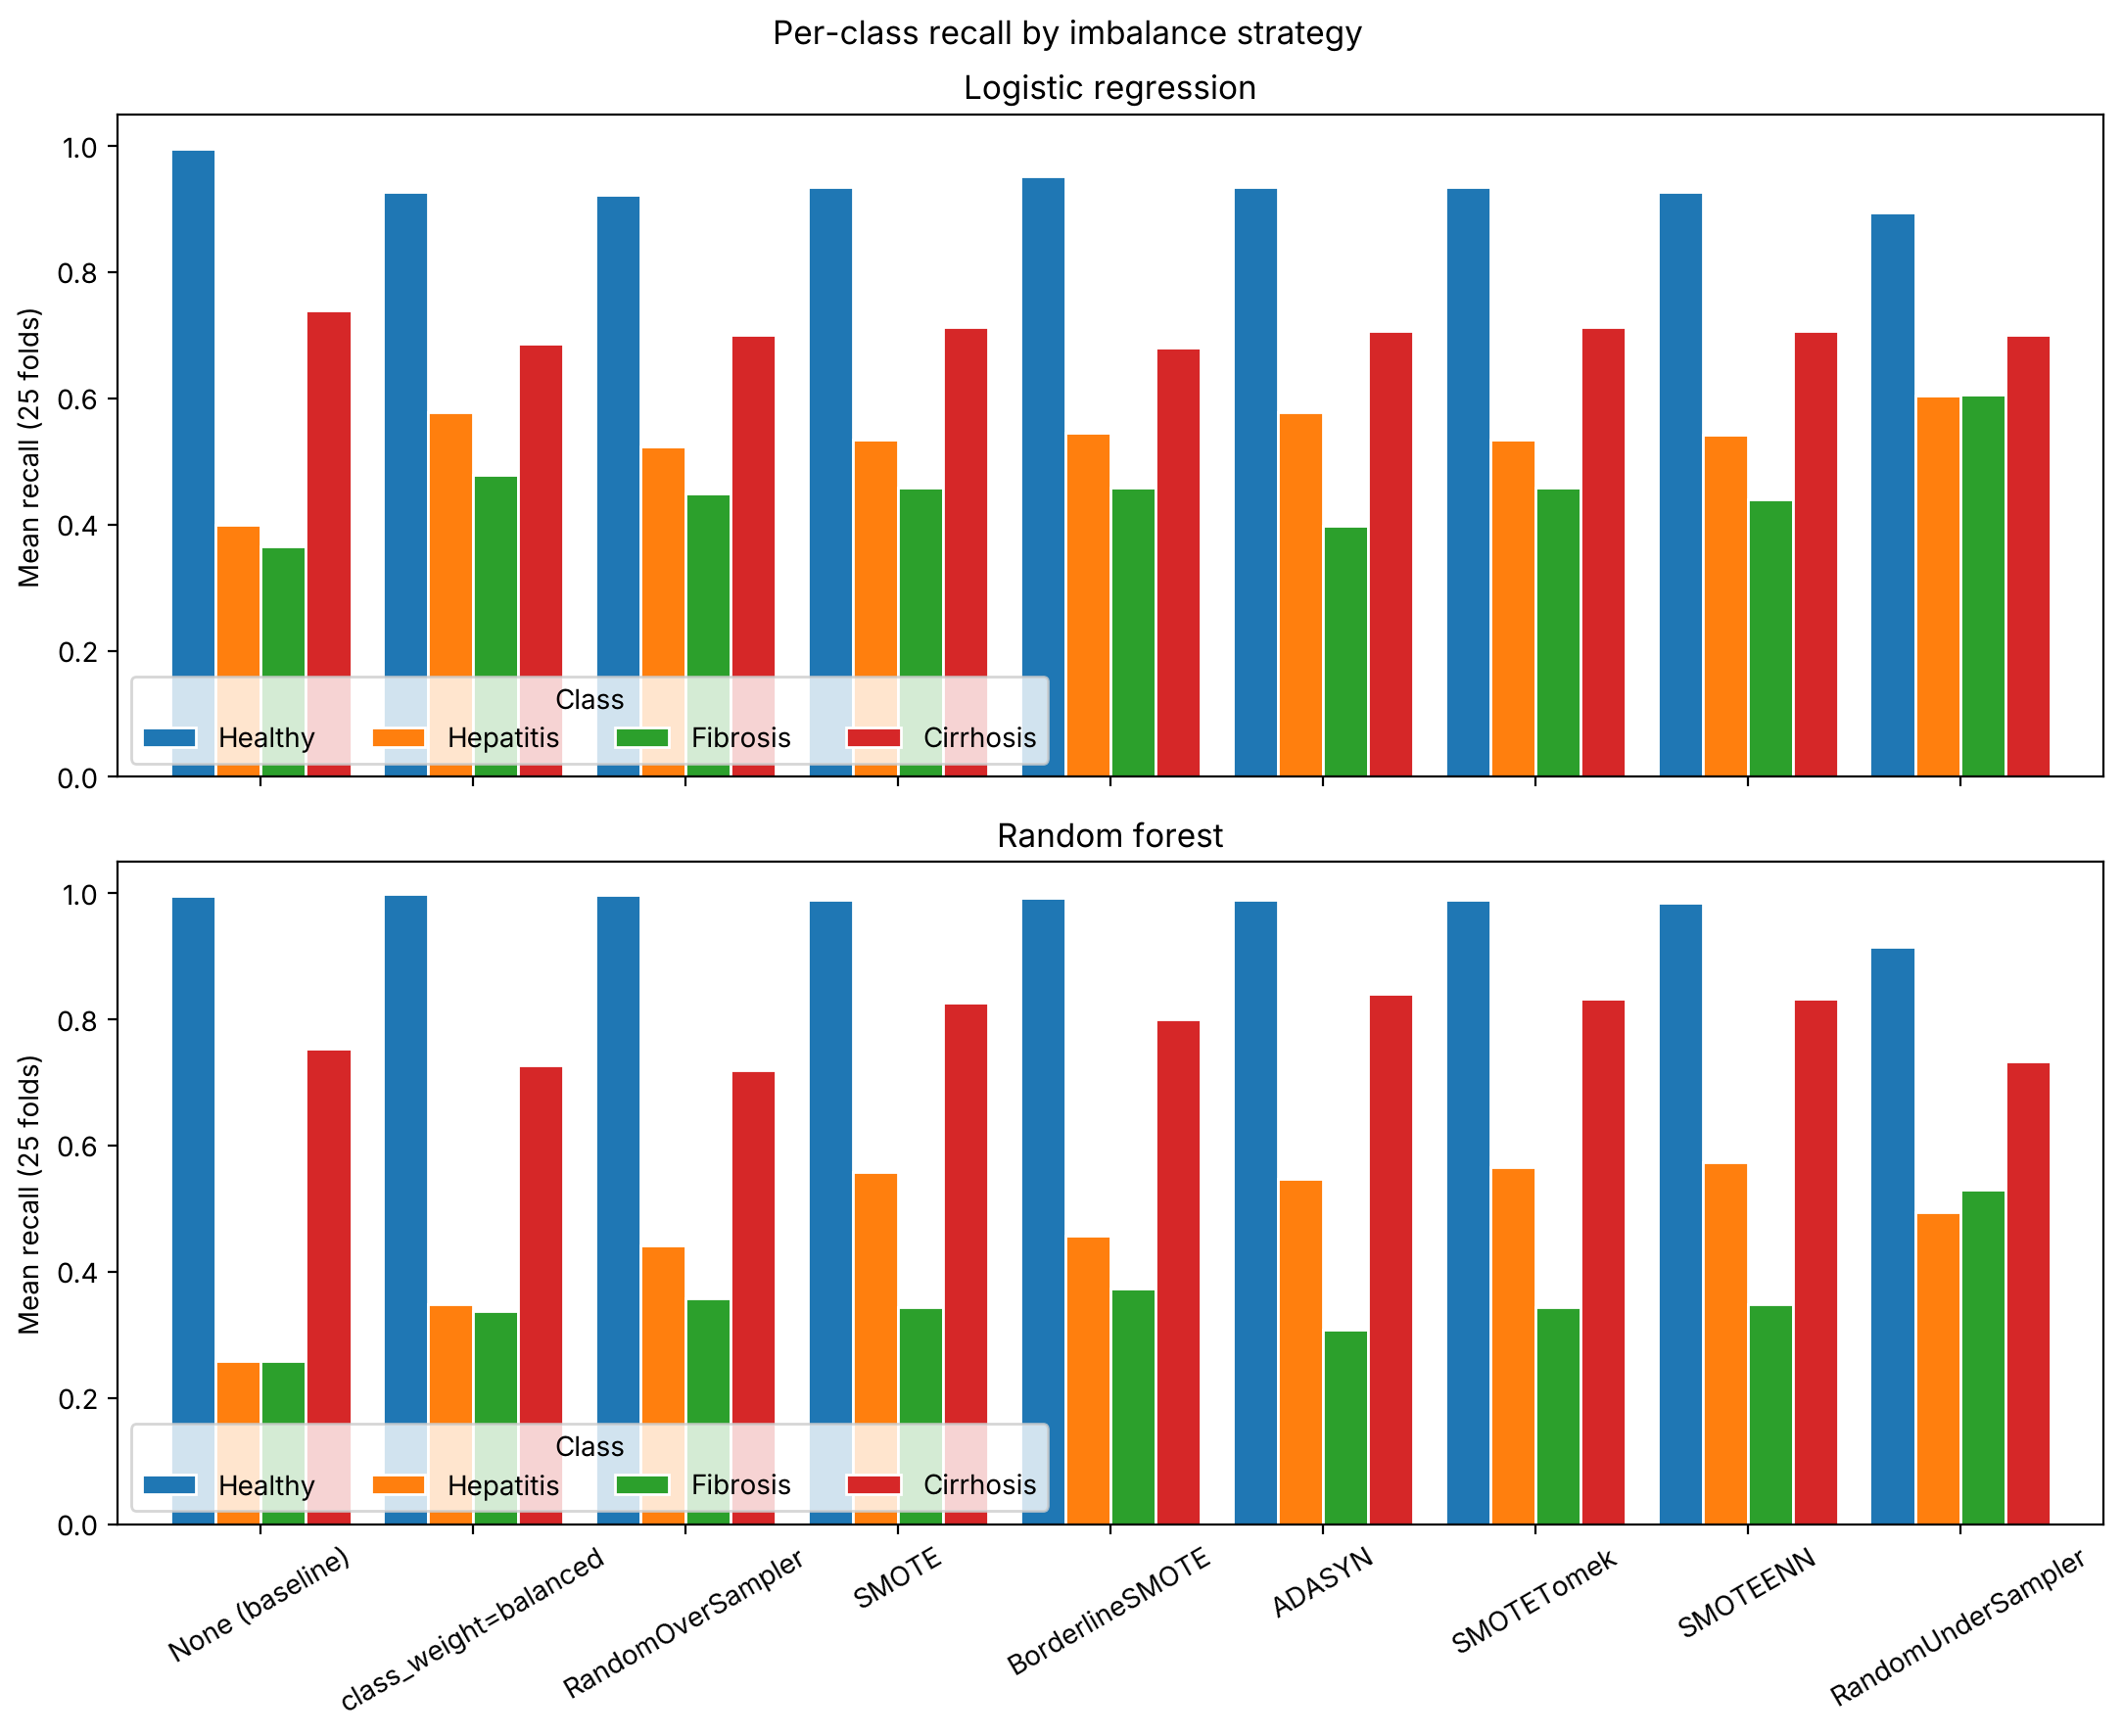

In [13]:
# one panel per model; bars are grouped by strategy, coloured by class
fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)
for ax, model_name in zip(axes, MODELS):
    recall = mean_table.loc[model_name][[f"recall_{c}" for c in CLASSES]]
    recall.columns = CLASSES
    recall.plot.bar(ax=ax, width=0.85, edgecolor="white")

    # labels and a common 0-1 scale make the two panels comparable
    ax.set_title(model_name)
    ax.set_ylabel("Mean recall (25 folds)")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Class", ncol=4, loc="lower left")
fig.suptitle("Per-class recall by imbalance strategy")
fig.tight_layout()
plt.show()

## Confusion matrices

For the two best strategies of each model (by macro F1). Predictions come from the first five folds only, so each patient is predicted once.

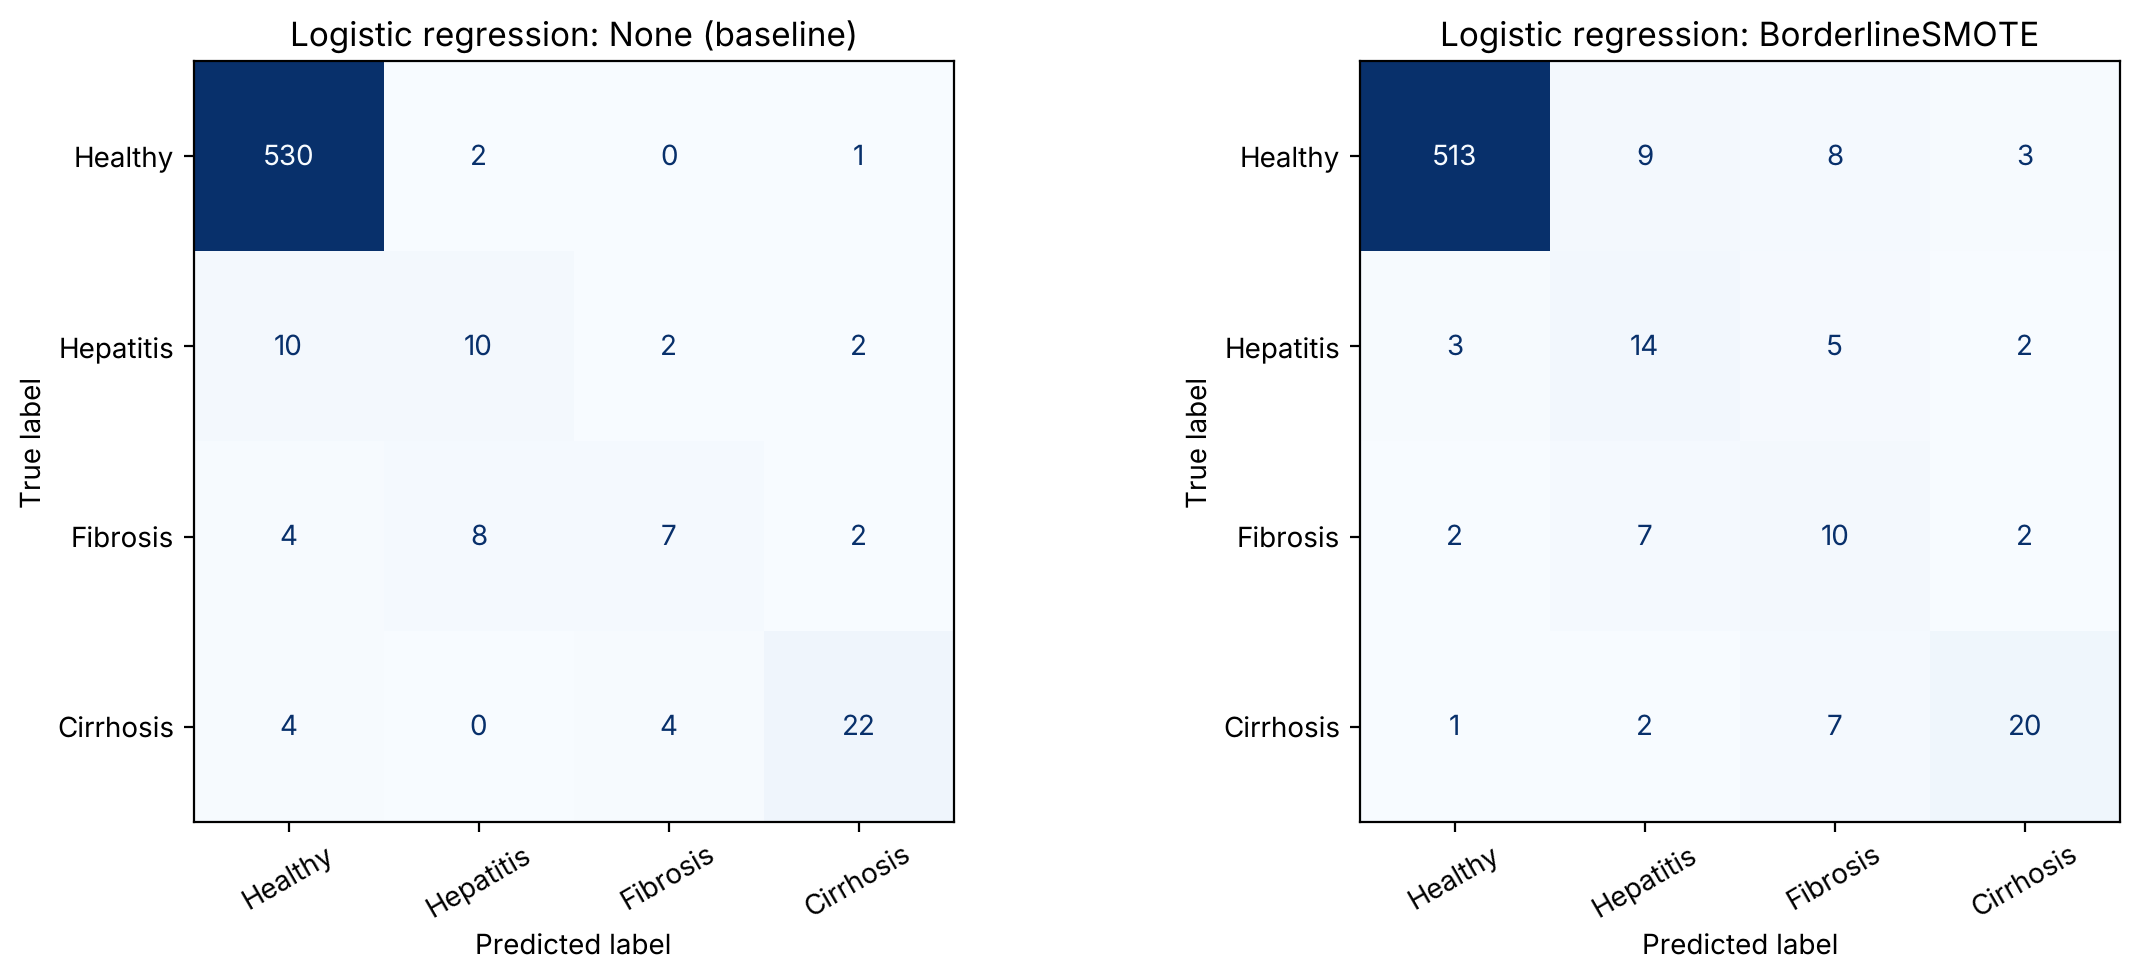

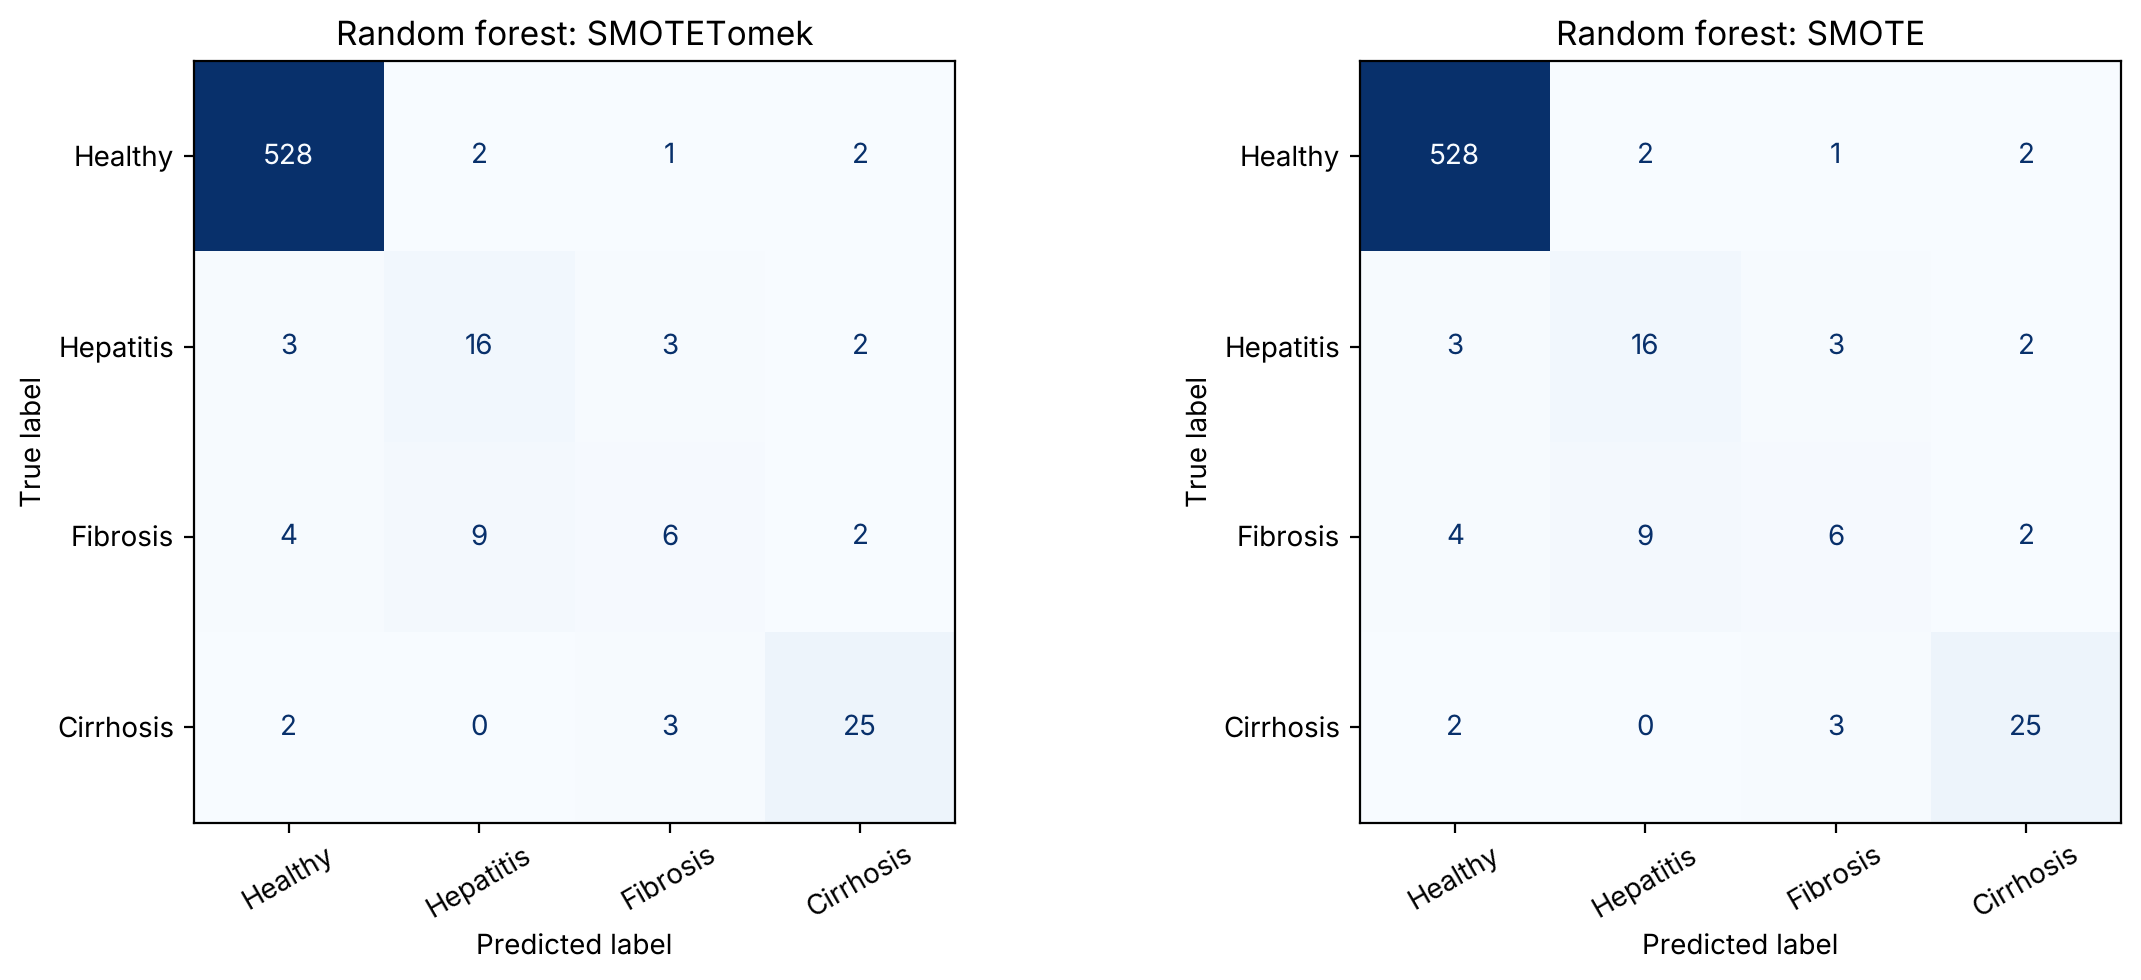

In [14]:
# for each model, pick the two strategies with the highest macro F1
for model_name in MODELS:
    top_two = mean_table.loc[model_name]["macro_f1"].nlargest(2).index
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, strategy in zip(axes, top_two):
        # use only the first repeat (the first 5 splits) so that every
        # patient appears in exactly one test fold and is predicted once
        pipeline = PIPELINES[(model_name, strategy)]
        predicted = cross_val_predict(pipeline, X, y, cv=SPLITS[:N_SPLITS])

        # draw the confusion matrix: rows are true, columns predicted
        ConfusionMatrixDisplay.from_predictions(
            y, predicted, labels=CLASSES, ax=ax, colorbar=False,
            cmap="Blues")
        ax.set_title(f"{model_name}: {strategy}")
        ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    plt.show()

## Experiment: models built for imbalance (no resampling)

Some models deal with rare classes themselves, without synthetic samples. Five are tested on the same 25 splits: a random forest with `balanced_subsample` weights, Balanced Random Forest, EasyEnsemble, RUSBoost and gradient boosting with balanced class weights.

In [15]:
# models that handle imbalance internally. None needs a separate sampler
EXPERIMENTAL_MODELS = {
    "RF balanced_subsample": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2,
        class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "Balanced Random Forest": BalancedRandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, random_state=SEED,
        n_jobs=-1),
    "EasyEnsemble": EasyEnsembleClassifier(
        n_estimators=10, random_state=SEED),
    # the default depth-1 trees failed to fit in 4 of the 25 folds
    # (worse than random on four classes), so depth 3 is used
    "RUSBoost": RUSBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        random_state=SEED),
    "HistGradientBoosting balanced": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=SEED),
}

# run each model on the same 25 splits, using the same preprocessing
# resampling inside these models happens in the training folds only
experiment_frames = []
for model_name, model in EXPERIMENTAL_MODELS.items():
    pipeline = Pipeline([("prep", preprocess), ("clf", clone(model))])
    scores = cross_validate(
        pipeline, X, y, cv=SPLITS, scoring=SCORING, error_score="raise")

    # keep the test scores only and label them, as in the earlier runs
    table = pd.DataFrame({
        name[len("test_"):]: values
        for name, values in scores.items() if name.startswith("test_")
    })
    table.insert(0, "fold", range(len(table)))
    table.insert(0, "strategy", "internal handling")
    table.insert(0, "model", model_name)
    experiment_frames.append(table)
experiment = pd.concat(experiment_frames, ignore_index=True)
print(f"Fold-level rows: {len(experiment)}")

Fold-level rows: 125


### Comparison with the resampling results

Mean (SD) over the 25 folds, next to the best results from the sections above.

In [16]:
# pick the reference rows from the earlier results table
reference_pairs = [
    ("Random forest", BASELINE), ("Random forest", "SMOTE"),
    ("Random forest", "SMOTEENN"), ("Logistic regression", BASELINE),
    ("Logistic regression", "class_weight=balanced"),
    ("Logistic regression", "RandomUnderSampler"),
]
keep = [
    ((results["model"] == m) & (results["strategy"] == s))
    for m, s in reference_pairs
]
reference = results[np.logical_or.reduce(keep)].copy()

# label every row as "model + strategy" so all runs sit in one table
reference["model"] = reference["model"] + " + " + reference["strategy"]
combined = pd.concat([reference, experiment], ignore_index=True)

# mean and SD per run, sorted by macro F1 (best first)
grouped = combined.groupby("model", sort=False)[METRICS]
mean_exp = grouped.mean()
sd_exp = grouped.std()
order = mean_exp["macro_f1"].sort_values(ascending=False).index
display((mean_exp.round(3).astype(str) + " ("
         + sd_exp.round(3).astype(str) + ")").loc[order])

,macro_f1,balanced_accuracy,macro_precision,recall_Healthy,recall_Hepatitis,recall_Fibrosis,recall_Cirrhosis
model,,,,,,,
Random forest + SMOTE,0.677 (0.082),0.68 (0.078),0.718 (0.12),0.99 (0.011),0.558 (0.276),0.344 (0.237),0.827 (0.148)
Random forest + SMOTEENN,0.677 (0.06),0.685 (0.056),0.722 (0.105),0.985 (0.013),0.574 (0.259),0.348 (0.208),0.833 (0.144)
Logistic regression + None (baseline),0.653 (0.082),0.625 (0.081),0.75 (0.116),0.995 (0.005),0.4 (0.199),0.366 (0.184),0.74 (0.205)
RF balanced_subsample,0.651 (0.102),0.608 (0.101),0.772 (0.132),1.0 (0.002),0.34 (0.184),0.358 (0.254),0.733 (0.18)
HistGradientBoosting balanced,0.643 (0.089),0.637 (0.091),0.687 (0.106),0.996 (0.006),0.478 (0.236),0.328 (0.23),0.747 (0.199)
Balanced Random Forest,0.634 (0.074),0.697 (0.077),0.604 (0.075),0.941 (0.029),0.506 (0.237),0.534 (0.216),0.807 (0.171)
Logistic regression + RandomUnderSampler,0.608 (0.047),0.701 (0.056),0.587 (0.048),0.894 (0.041),0.604 (0.23),0.606 (0.176),0.7 (0.22)
Logistic regression + class_weight=balanced,0.602 (0.062),0.667 (0.073),0.584 (0.071),0.927 (0.028),0.578 (0.235),0.478 (0.168),0.687 (0.227)
Random forest + None (baseline),0.59 (0.091),0.566 (0.085),0.657 (0.13),0.996 (0.005),0.258 (0.229),0.258 (0.187),0.753 (0.199)


### Paired differences against RF + SMOTE

Each model is compared fold by fold with random forest plus SMOTE, using a Wilcoxon signed-rank test with Bonferroni adjustment for the five models.

In [17]:
# reference scores: random forest + SMOTE on the 25 folds
smote_rows = results[(results["model"] == "Random forest")
                     & (results["strategy"] == "SMOTE")]
rows = []
for model_name in EXPERIMENTAL_MODELS:
    model_rows = experiment[experiment["model"] == model_name]
    for metric in ["macro_f1", "balanced_accuracy"]:
        # A positive difference means better than RF + SMOTE
        diff = (model_rows[metric].to_numpy()
                - smote_rows[metric].to_numpy())
        rows.append({"model": model_name, "metric": metric,
                     "mean_diff": diff.mean(),
                     "p_raw": wilcoxon(diff).pvalue})
versus_smote = pd.DataFrame(rows)

# Bonferroni: multiply by the number of models tested (5), cap at 1
versus_smote["p_adj"] = (
    versus_smote["p_raw"] * len(EXPERIMENTAL_MODELS)).clip(upper=1)
versus_smote["significant"] = versus_smote["p_adj"] < ALPHA
versus_smote[["mean_diff", "p_raw", "p_adj"]] = versus_smote[
    ["mean_diff", "p_raw", "p_adj"]].round(4)
display(versus_smote)

,model,metric,mean_diff,p_raw,p_adj,significant
0,RF balanced_subsample,macro_f1,-0.0255,0.1073,0.5366,False
1,RF balanced_subsample,balanced_accuracy,-0.0719,0.0013,0.0065,True
2,Balanced Random Forest,macro_f1,-0.0431,0.0147,0.0736,False
3,Balanced Random Forest,balanced_accuracy,0.0174,0.2996,1.0000,False
4,EasyEnsemble,macro_f1,-0.1378,0.0000,0.0000,True
5,EasyEnsemble,balanced_accuracy,-0.0352,0.0393,0.1967,False
6,RUSBoost,macro_f1,-0.1215,0.0000,0.0000,True
7,RUSBoost,balanced_accuracy,-0.0390,0.0903,0.4516,False
8,HistGradientBoosting balanced,macro_f1,-0.0332,0.0422,0.2108,False
9,HistGradientBoosting balanced,balanced_accuracy,-0.0425,0.0097,0.0486,True


### Findings

None of the five models beat random forest with SMOTE or SMOTEENN on macro F1 (best of the five: 0.651, against 0.677 for both). EasyEnsemble and RUSBoost were clearly worse because they flag many healthy patients (Healthy recall 0.826 and 0.887). The Balanced Random Forest had the best Fibrosis recall of the forest models (0.534 against 0.344) but a lower Healthy recall (0.941).

## Findings

Random forest improved with the SMOTE-type methods (macro F1 0.590 to about 0.68). Logistic regression did not improve on macro F1 with any strategy. Fibrosis recall stayed below 0.61 for every strategy. The full write-up is in `findings.md`.